Import the modules that will be used.

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

## Dot product of two vectors:

$n$ operations will occur as each value is multiplied by its corresponding value. Therefore the time scale linearly with $n$

$t = O(n)$


## Matrix-vector product:

The result of this will be a vector of length $n$, each of these vectors will have been made by the sum of n discrete operations

Therefore $n \times n$, $t = O(n^2)$

## Matrix-Matrix product:

$n \times n$ different values will be made, each by the multiplication of a row and column of $n$ elements, so the time is proportional to $n$ cubed

$ t = O(n^3)$



## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [2]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

[1.2354200043773745e-07, 2.1529200057557317e-07, 2.958330005640164e-07, 4.1312499888590536e-07, 4.5733300066785886e-07, 5.336249996616971e-07, 6.09541999438079e-07, 6.853750001027947e-07, 7.614170008309884e-07]


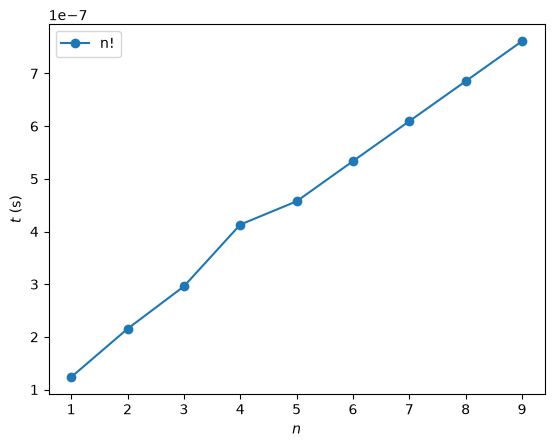

In [3]:
import numpy as np
import matplotlib.pyplot as plt
vals = np.arange(1, 10)

times = []
for val in vals:
    t = %timeit -n1000 -r100 -q -o factorial(val)
    times.append(t.best)

print(times)

plt.plot(vals, times, marker='o', label='n!')
plt.xlabel('$n$')
plt.ylabel('$t$ (s)')


# Add legend
plt.legend(loc=0)

plt.show()

This appears to be approximately linear when $n$ is large, so $t=O(n)$ seems reasonable

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [4]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [5]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [6]:
# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 13)
times = []
for i in range(0, len(N)):
    array = np.random.rand(N[i],N[i])
    t = %timeit -n10 -r1 -q -o np.linalg.slogdet(array)
    times.append(t.best)


Plot result:

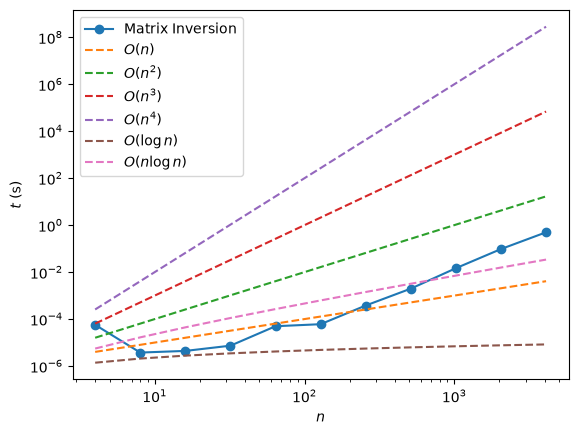

In [7]:

plt.loglog(N, times, marker='o', label=r'Matrix Inversion')
plt.xlabel('$n$')
plt.ylabel('$t$ (s)')

plt.loglog(N, 1e-6*N, '--', label=r'$O(n$)')
plt.loglog(N, 1e-6*N**2, '--', label=r'$O(n^2$)')
plt.loglog(N, 1e-6*N**3, '--', label=r'$O(n^3$)')
plt.loglog(N, 1e-6*N**4, '--', label=r'$O(n^4$)')
plt.loglog(N, 1e-6*np.log(N), '--', label=r'$O(\log n)$')
plt.loglog(N, 1e-6*N*np.log(N), '--', label=r'$O(n\log n)$')





plt.legend(loc=0);


plt.show()

## Big Oh value of matrix inversion:

The time against $n$ plot of the matrix inversion appears parallel with $n^3$

Therfore $t = O(n^3)$